# 11 — Benchmark ajustado por características del edificio

## Objetivo

El benchmark jerárquico (notebook 03) compara cada aviso con otros del mismo barrio, ambientes y superficie, pero **no considera antigüedad ni amenities** (cochera, pileta, ascensor, etc.). Un aviso puede parecer "barato" simplemente porque es más viejo o tiene menos características que sus comparables.

En esta notebook se evalúa si incorporar esas variables mejora la estimación del precio esperado y cómo cambia, en consecuencia, la lista de oportunidades. Se usa la regresión hedónica de la notebook 10 como benchmark ajustado, **con predicciones fuera de muestra** (validación cruzada de 5 pliegues), de modo que ningún aviso se predice con un modelo que lo haya visto.

## Preguntas

1. ¿El benchmark ajustado estima mejor el USD/m² que el benchmark jerárquico?
2. ¿Cuántas "baratas" del benchmark original se explican por antigüedad y características?
3. ¿El Precio Esperado Reciclado (PER) usado en el modelo económico es consistente con el que surge del modelo?

In [2]:
# ENTORNO Y CARGA
import os, sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import BASE_FEATURES, PROCESSED_DIR, UMBRAL_GAP
from src.modelos import (preparar_base_modelo, prediccion_cruzada, comparar_precision,
                         clasificar_barata_doble, CARACTERISTICAS)

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

df = pd.read_csv(BASE_FEATURES)
d = preparar_base_modelo(df)
d = d[d["Benchmark_USD_m2"].notna()].copy()      # avisos con benchmark jerárquico

d = prediccion_cruzada(d, k=5, semilla=7)
d = d[d["Pred_USD_m2_Propio"].notna()].copy()    # se descartan barrios sin avisos en el ajuste
print("Avisos evaluados:", len(d))

Avisos evaluados: 9194


## 1. Precisión: benchmark jerárquico vs. benchmark ajustado

Se compara el error porcentual absoluto (MAPE y MdAPE) de cada estimación frente al USD/m² publicado. El benchmark jerárquico usa *leave-one-out* (no se incluye a sí mismo) y el ajustado, predicción fuera de muestra, por lo que la comparación es entre estimaciones que no vieron el aviso evaluado.

In [3]:
pred = {"Benchmark jerárquico": "Benchmark_USD_m2", "Benchmark ajustado (hedónico)": "Pred_USD_m2_Propio"}

print("Todos los avisos")
display(comparar_precision(d, pred))

for estado in ["Buen_estado", "Reciclada_refaccionada"]:
    print(f"\nSolo avisos en estado {estado}")
    display(comparar_precision(d[d["Estado_Propiedad"].eq(estado)], pred))

Todos los avisos


,N,MAPE (%),MdAPE (%)
Benchmark jerárquico,"9,194.00",19.63,14.76
Benchmark ajustado (hedónico),"9,194.00",15.29,11.64



Solo avisos en estado Buen_estado


,N,MAPE (%),MdAPE (%)
Benchmark jerárquico,"1,992.00",17.66,12.94
Benchmark ajustado (hedónico),"1,992.00",13.97,10.51



Solo avisos en estado Reciclada_refaccionada


,N,MAPE (%),MdAPE (%)
Benchmark jerárquico,952.00,17.84,14.78
Benchmark ajustado (hedónico),952.00,15.22,12.30


### Interpretación

Incorporar antigüedad, amenities y estado reduce el error de estimación de forma consistente: el **MAPE baja de 19,6% a 15,3%** (y el MdAPE de 14,8% a 11,6%). La mejora aparece también al mirar por separado los avisos en buen estado (17,7% → 14,0%) y los reciclados (17,8% → 15,2%), por lo que no depende de un solo grupo.

Un error mediano de ~12% es un piso razonable para precios de publicación: el modelo no ve la calidad de terminación, el piso, la orientación ni la negociación, así que no debe leerse como un valor de tasación.

**Conclusión:** el benchmark ajustado estima mejor el precio esperado que el jerárquico, y sirve como segunda opinión para validar las oportunidades.

## 2. Qué cambia en la detección de oportunidades

Se cruzan dos brechas, ambas expresadas como % por debajo de lo esperado: la del benchmark jerárquico y la del benchmark ajustado. Se consideran avisos que **no** necesitan obra (los que sí la necesitan se analizan con el PER). El umbral es el mismo del proyecto (`UMBRAL_GAP`).

,Avisos,%
Categoria_Doble,,
No_barata,7704,87.80
Solo_benchmark,476,5.40
Confirmada_por_ambos,325,3.70
Solo_hedonico,272,3.10


Baratas según el benchmark jerárquico: 801
  de las cuales siguen siéndolo con el ajuste: 325 (40.6%)
Spearman entre ambas brechas: 0.66


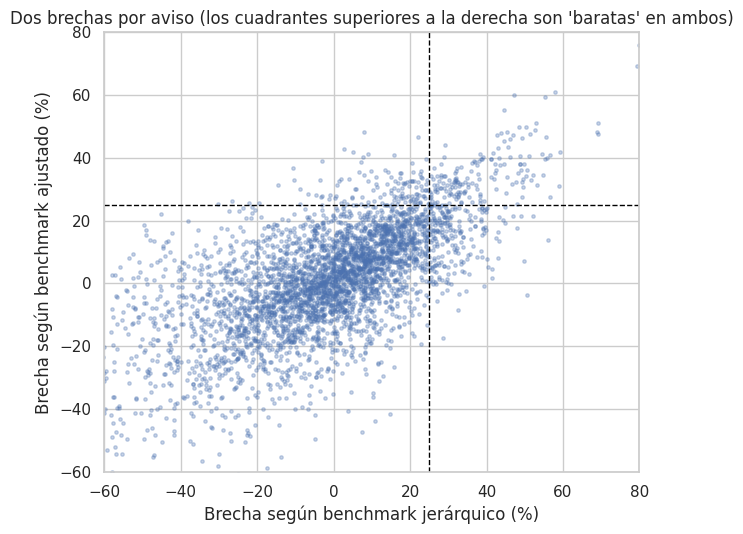

In [4]:
d = clasificar_barata_doble(d, umbral_gap=UMBRAL_GAP)
sin_obra = d[d["Categoria_Doble"].notna()]

tabla = (sin_obra["Categoria_Doble"].value_counts()
         .rename("Avisos").to_frame())
tabla["%"] = (tabla["Avisos"] / tabla["Avisos"].sum() * 100).round(1)
display(tabla)

baratas_bm = sin_obra[sin_obra["Categoria_Doble"].isin(["Confirmada_por_ambos", "Solo_benchmark"])]
print(f"Baratas según el benchmark jerárquico: {len(baratas_bm)}")
print(f"  de las cuales siguen siéndolo con el ajuste: {(baratas_bm['Categoria_Doble'] == 'Confirmada_por_ambos').sum()} "
      f"({(baratas_bm['Categoria_Doble'] == 'Confirmada_por_ambos').mean() * 100:.1f}%)")
print(f"Spearman entre ambas brechas: {stats.spearmanr(sin_obra['Gap_Benchmark_pct'], sin_obra['Gap_Hedonico_pct'])[0]:.2f}")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
muestra = sin_obra.sample(min(4000, len(sin_obra)), random_state=1)
ax.scatter(muestra["Gap_Benchmark_pct"], muestra["Gap_Hedonico_pct"], s=6, alpha=0.3)
ax.axvline(UMBRAL_GAP, color="black", linestyle="--", linewidth=1)
ax.axhline(UMBRAL_GAP, color="black", linestyle="--", linewidth=1)
ax.set(xlim=(-60, 80), ylim=(-60, 80), xlabel="Brecha según benchmark jerárquico (%)",
       ylabel="Brecha según benchmark ajustado (%)",
       title="Dos brechas por aviso (los cuadrantes superiores a la derecha son 'baratas' en ambos)")
plt.tight_layout()
plt.show()

### ¿Por qué se pierden oportunidades al ajustar?

Se compara el perfil de las baratas **confirmadas por ambos métodos** con las que lo son **solo según el benchmark**: si estas últimas tienen más antigüedad y menos amenities, su descuento tiene una explicación observable.

In [5]:
perfil = sin_obra[sin_obra["Categoria_Doble"].isin(["Confirmada_por_ambos", "Solo_benchmark", "No_barata"])].copy()
perfil["Cantidad_amenities"] = perfil[CARACTERISTICAS].sum(axis=1)
perfil["Antiguedad_mas_50"] = perfil["Banda_Antiguedad"].eq("Mas_50").astype(int)
perfil["Antiguedad_hasta_10"] = perfil["Banda_Antiguedad"].eq("Hasta_10").astype(int)

resumen = perfil.groupby("Categoria_Doble").agg(
    Avisos=("ID", "size"),
    Amenities_promedio=("Cantidad_amenities", "mean"),
    Pct_con_cochera=("Cochera_Incluida", lambda s: s.mean() * 100),
    Pct_con_ascensor=("Ascensor", lambda s: s.mean() * 100),
    Pct_antiguedad_mas_50=("Antiguedad_mas_50", lambda s: s.mean() * 100),
    Pct_antiguedad_hasta_10=("Antiguedad_hasta_10", lambda s: s.mean() * 100),
).loc[["Confirmada_por_ambos", "Solo_benchmark", "No_barata"]]
display(resumen.round(1))

,Avisos,Amenities_promedio,Pct_con_cochera,Pct_con_ascensor,Pct_antiguedad_mas_50,Pct_antiguedad_hasta_10
Categoria_Doble,,,,,,
Confirmada_por_ambos,325,3.70,18.80,43.70,40.00,10.20
Solo_benchmark,476,3.20,10.10,36.10,42.40,8.00
No_barata,7704,4.60,27.30,53.60,31.60,19.50


### Interpretación

De las **801 propiedades baratas** según el benchmark jerárquico (brecha ≥ 25 % y cuartil inferior de sus comparables, la definición completa del proyecto), solo **325 (41%)** siguen siéndolo al controlar por antigüedad y características; las otras 476 tienen un descuento que el modelo explica en buena parte. A su vez, 271 avisos que el benchmark original no marcaba aparecen como baratas con el ajuste.

El perfil es coherente: las que solo son baratas según el benchmark tienen menos amenities (3,3 contra 3,7 en promedio) y bastante menos cochera (11% contra 19%) que las confirmadas por ambos métodos; la antigüedad, en cambio, no las distingue (ambas tienen ~40% de edificios de más de 50 años). Es decir, una parte del descuento se asocia a no tener cochera u otros atributos y no a una oportunidad de precio.

**Uso en el proyecto:** las 325 **baratas según ambos métodos** son las candidatas con mayor confianza para priorizar y deben señalarse como tales en el ranking y el dashboard. Las que solo marca el benchmark no se descartan (el modelo tiene un error de ~12-15%), pero requieren más verificación.

**Limitación:** el modelo controla las características publicadas; no ve estado de conservación del edificio, piso ni terminaciones, por lo que "explicado por el modelo" no equivale a "sin oportunidad".

## 3. Consistencia del PER con el modelo

El Precio Esperado Reciclado (PER) estima cuánto valdría una propiedad que hoy necesita obra una vez reciclada, y es la base del modelo económico. Acá se lo contrasta con el precio que predice el modelo hedónico para la misma propiedad si estuviera `Reciclada_refaccionada`, también fuera de muestra.

Propiedades que necesitan obra con PER y predicción: 411


,Valor
PER_Base mediano (USD),"112,746.62"
PER hedónico mediano (USD),"118,345.35"
Razón mediana (hedónico / PER_Base),1.04
Razón P25,0.96
Razón P75,1.13
Spearman,0.97
% con diferencia absoluta > 20%,14.60


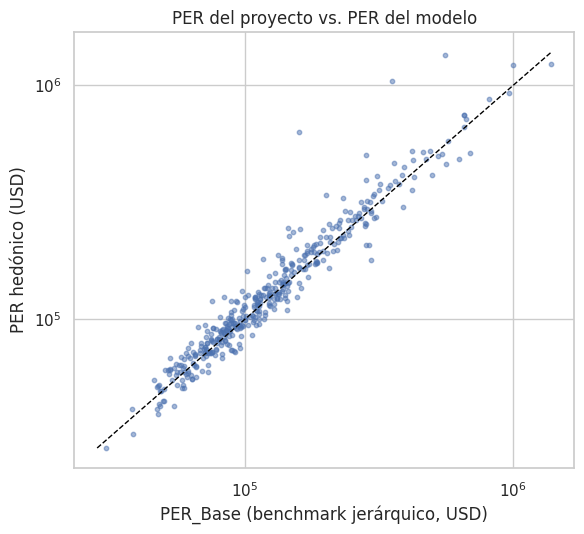

In [6]:
obra = d[d["Estado_Propiedad"].eq("Necesita_obra") & d["PER_Base"].notna()].copy()
obra["PER_Hedonico"] = obra["Pred_USD_m2_Reciclado"] * obra["Superficie_Homogeneizada_m2"]
obra["Razon"] = obra["PER_Hedonico"] / obra["PER_Base"]

print(f"Propiedades que necesitan obra con PER y predicción: {len(obra)}")
display(pd.Series({
    "PER_Base mediano (USD)": obra["PER_Base"].median(),
    "PER hedónico mediano (USD)": obra["PER_Hedonico"].median(),
    "Razón mediana (hedónico / PER_Base)": obra["Razon"].median(),
    "Razón P25": obra["Razon"].quantile(0.25),
    "Razón P75": obra["Razon"].quantile(0.75),
    "Spearman": stats.spearmanr(obra["PER_Base"], obra["PER_Hedonico"])[0],
    "% con diferencia absoluta > 20%": (obra["Razon"].sub(1).abs() > 0.20).mean() * 100,
}).to_frame("Valor"))

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(obra["PER_Base"], obra["PER_Hedonico"], s=10, alpha=0.5)
lim = [obra[["PER_Base", "PER_Hedonico"]].min().min(), obra[["PER_Base", "PER_Hedonico"]].max().max()]
ax.plot(lim, lim, color="black", linestyle="--", linewidth=1)
ax.set(xscale="log", yscale="log", xlabel="PER_Base (benchmark jerárquico, USD)",
       ylabel="PER hedónico (USD)", title="PER del proyecto vs. PER del modelo")
plt.tight_layout()
plt.show()

### Interpretación

El PER hedónico es en mediana **4% mayor** que el PER del proyecto (razón mediana 1,04, con rango intercuartil 0,96-1,13) y ambos ordenan las propiedades de forma casi idéntica (Spearman 0,97). Solo el 15% de las propiedades difiere en más de 20%.

**Conclusión:** el PER del modelo económico es **consistente** con una estimación que controla por antigüedad y características; si algo, es levemente más bajo. Eso es consistencia interna, no ausencia de sesgo: los dos se estiman sobre los mismos avisos y con precios de publicación, así que comparten cualquier sesgo de la fuente (por ejemplo, que los avisos reciclados se publiquen por encima de su precio de cierre). Para afirmar que el PER no está sesgado haría falta contrastarlo con precios de cierre o tasaciones externas. El PER sigue siendo un precio de publicación y no de cierre.

In [7]:
# EXPORTACIÓN: brechas y categoría por aviso, para el ranking y el dashboard
salida = d[["ID", "Barrio_Oficial", "Estado_Propiedad", "USD_m2_Homogeneizado", "Benchmark_USD_m2",
            "Pred_USD_m2_Propio", "Pred_USD_m2_Reciclado", "Gap_Benchmark_pct", "Gap_Hedonico_pct",
            "Categoria_Doble"]].copy()
destino = PROCESSED_DIR / "oportunidades_benchmark_ajustado.csv"
salida.to_csv(destino, index=False)
print("Guardado:", destino.relative_to(RAIZ), "-", len(salida), "filas")

Guardado: data/processed/oportunidades_benchmark_ajustado.csv - 9194 filas


## Conclusiones

1. **Precisión:** el benchmark ajustado por antigüedad y características reduce el MAPE de 19,6% a 15,3% (fuera de muestra).
2. **Oportunidades:** solo el 41% de las baratas del benchmark jerárquico (325 de 801) lo siguen siendo al ajustar; el resto se asocia a menos amenities, en particular cochera. Las 325 baratas según ambos métodos son las de mayor confianza; como los dos se estiman sobre los mismos datos, su coincidencia indica consistencia, no una confirmación independiente.
3. **PER:** es consistente con el modelo (razón mediana 1,04; Spearman 0,97). Esto muestra consistencia interna, no ausencia de sesgo: ambos usan los mismos precios de publicación.
4. **Archivo generado:** `data/processed/oportunidades_benchmark_ajustado.csv` (brechas y categoría por aviso), para el ranking y el dashboard.

### Limitaciones

- Precios de publicación, no de cierre.
- El modelo no observa estado del edificio, piso, orientación ni terminaciones.
- Las brechas dependen del umbral (`UMBRAL_GAP` = 25%); se mantiene el del proyecto para que sea comparable.
- Un modelo con error mediano de ~12% no sirve como tasación individual; se usa para priorizar y contrastar.